# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170423         # <-- your full roll number
NAME = "Ashirwad Khatri"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170423   Name: Ashirwad Khatri   Fingerprint: 470A2DA1   Tickets: 15

Ticket_ID                                                                                  Ticket_Text
      T01                                 The student portal crashes while opening. Please resolve it.
      T02                        Laptop is running slowly before the assignment deadline. Please help.
      T03                                                   The Python is running slowly. Please help.
      T04                               I can't open the LMS while uploading the file. This is urgent.
      T05                                     The Python is running slowly. I don't know what changed.
      T06                  I tried restarting the email while uploading the file. It worked yesterday.
      T07 Printer crashes while opening when connected to campus Wi-Fi. The same problem occurs again.
      T08                                                        It's not the laptop; it'

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import RegexpTokenizer
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

tickets = df['Ticket_Text'].tolist()
res = [process_ticket(t) for t in tickets]

rows = []
for tid, r in zip(df['Ticket_ID'], res):
    rows.append({'Ticket_ID': tid, 'sentences': len(r['sentences']), 'tokens': len(r['tokens']),
                 'punct': len(r['punct']), 'stopwords': len(r['stops']),
                 'unique_tokens': len(set(r['tokens'])), 'final_tokens': len(r['final'])})
tab = pd.DataFrame(rows)
tab.loc[len(tab)] = ['TOTAL'] + tab.drop(columns='Ticket_ID').sum().tolist()
display(tab)

k = 5
print(tickets[k])
print('tokens:', res[k]['tokens'])
print('punct:', res[k]['punct'])
print('stopwords:', res[k]['stops'])
print('final:', res[k]['final'])

,Ticket_ID,sentences,tokens,punct,stopwords,unique_tokens,final_tokens
0,T01,2,11,2,3,10,6
1,T02,2,12,2,3,11,7
2,T03,2,9,2,2,8,5
3,T04,2,15,2,6,13,7
4,T05,2,13,2,5,12,6
5,T06,2,14,2,5,12,7
6,T07,2,16,2,6,15,8
7,T08,1,11,2,5,8,4
8,T09,1,10,1,3,10,6
9,T10,2,8,2,1,7,5


I tried restarting the email while uploading the file. It worked yesterday.
tokens: ['i', 'tried', 'restarting', 'the', 'email', 'while', 'uploading', 'the', 'file', '.', 'it', 'worked', 'yesterday', '.']
punct: ['.', '.']
stopwords: ['i', 'the', 'while', 'the', 'it']
final: ['tried', 'restarting', 'email', 'uploading', 'file', 'worked', 'yesterday']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer: Non-words in the final tokens are n't (3 times) and wo, plus number/ID tokens like +91, 98765, 43210, 0175-239-3201 and 95.5. n't and wo come from word_tokenize splitting contractions (don’t → do + n’t, won’t → wo + n’t, isn’t → is + n’t). The stopword list contains neither, so they survive as final tokens. The phone numbers come from tokenizing at spaces and hyphens.*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

long_words = r'\b[A-Za-z]{6,}\b'
numbers = r'\b\d+(?:[.,]\d+)*\b'
capitalized = r'\b[A-Z][A-Za-z]*(?:-[A-Za-z]+)*\b'
vowel_words = r"\b[AEIOUaeiou][A-Za-z]*(?:'[a-z]+)?\b"
email = r'[\w.+-]+@[\w-]+(?:\.[\w-]+)+'
url = r'(?:https?://|www\.)[^\s<>"]*[^\s<>".,;:!?)]'
phone = r'\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|\b\d{3,5}-\d{3,4}-\d{4}\b'

def extract(text):
    return {'long': re.findall(long_words, text), 'numbers': re.findall(numbers, text),
            'capitalized': re.findall(capitalized, text), 'vowel': re.findall(vowel_words, text)}

def mask(text):
    text = re.sub(email, '<EMAIL>', text)
    text = re.sub(url, '<URL>', text)
    text = re.sub(phone, '<PHONE>', text)
    return text

for t in TEST_LINES + tickets:
    print(t)
    print(extract(t))
    print(mask(t))
    print()

total = sum(len(re.findall(capitalized, t)) for t in tickets)
start = sum(1 for t in tickets for s in nltk.sent_tokenize(t) if re.match(capitalized, s))
print(total, start)

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
{'long': ['helpdesk', 'thapar', 'thapar', 'thapar'], 'numbers': [], 'capitalized': ['Mail'], 'vowel': ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']}
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
{'long': ['Version'], 'numbers': ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250'], 'capitalized': ['Call', 'Version', 'Rs'], 'vowel': ['or', 'is']}
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
{'long': [], 'numbers': ['5.30'], 'capitalized': ['The'], 'vowel': ['of', 'art', "isn't", 'open', 'in', 'at']}
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

The student portal crashes while opening. 

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer: 28 capitalized words were found in the tickets, and 22 of them are capitalized only because they start a sentence (The, Can, It, I, Laptop, Server, …). Only 6 are capitalized by choice: Wi-Fi, Matlab, LMS, Not, Submitted and WiFi.*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
pattern = '|'.join([url, email, phone, r'\d+(?:[.,]\d+)+', r'(?:[A-Za-z]\.){2,}',
                    r"[A-Za-z0-9]+(?:[-'][A-Za-z0-9]+)*", r'[^\w\s]'])
tok = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tok.tokenize(text)

for t in TEST_LINES + tickets:
    a, b = my_tokenize(t), nltk.word_tokenize(t)
    print(t)
    print('mine:', a)
    print('nltk:', b)
    print('same' if a == b else 'DIFFERENT')
    print()

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
mine: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
nltk: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
DIFFERENT

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
mine: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
nltk: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
DIFFERENT

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
mine: ['The', 'state-of-the-art', 'lab', 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer: 3 of the 13 tickets differ. T04 (“I don’t know…”) and T10 (“won’t print; it isn’t jammed”) differ because word_tokenize splits contractions (do + n't, wo + n't, is + n't), while my_tokenize keeps them whole. T09 (“Call me on +91 98765 43210…”) differs because word_tokenize splits the phone number into +91, 98765 and 43210, while my_tokenize keeps it as one token. The other 10 tickets give identical output, since they contain only plain words, simple punctuation and 95.5. The difference shows up on TEST_LINES too, where emails and URLs are split by NLTK but kept whole by mine.*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
porter = PorterStemmer()
lancaster = LancasterStemmer()
regstem = RegexpStemmer('ing$|ed$|s$', min=4)
lemm = WordNetLemmatizer()

def wn_pos(tag):
    if tag.startswith('J'): return 'a'
    if tag.startswith('V'): return 'v'
    if tag.startswith('R'): return 'r'
    return 'n'

tags = {}
for r in res:
    for w, tg in nltk.pos_tag(r['tokens']):
        tags.setdefault(w, tg)

uniq = sorted(set(w for r in res for w in r['final']))
out = pd.DataFrame({
    'word': uniq,
    'porter': [porter.stem(w) for w in uniq],
    'lancaster': [lancaster.stem(w) for w in uniq],
    'regexp': [regstem.stem(w) for w in uniq],
    'lemma': [lemm.lemmatize(w, wn_pos(tags[w])) for w in uniq]
})
diff = out[out[['porter', 'lancaster', 'regexp', 'lemma']].nunique(axis=1) > 1]
display(diff)

,word,porter,lancaster,regexp,lemma
5,access,access,access,acces,access
6,assignment,assign,assign,assignment,assignment
9,campus,campu,camp,campu,campus
10,changed,chang,chang,chang,change
12,crashes,crash,crash,crashe,crash
13,deadline,deadlin,deadlin,deadline,deadline
16,file,file,fil,file,file
19,https,http,https,http,http
23,latest,latest,latest,latest,late
24,lms,lm,lms,lms,lm


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer: I chose ing$|ed$|s$ with min=4. In my tickets, opening, restarting and syncing are reduced to open, restart and sync. failed and uploaded become fail and upload, and keeps and works become keep and work. min=4 protects short words like lms. The weakness is that it cuts too much, as in stopped → stopp and crashes → crashe.*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,total,unique,TTR
S1,176,84,0.4773
S2,145,79,0.5448
S3,88,57,0.6477
S4,88,56,0.6364


[('.', 25), ('the', 15), ('i', 6), ('please', 5), ('it', 5), ('is', 5), ('while', 4), ('running', 4), ('slowly', 4), ('help', 4)]
[('please', 5), ('running', 4), ('slowly', 4), ('help', 4), ("n't", 3), ('yesterday', 3), ('crashes', 2), ('opening', 2), ('laptop', 2), ('python', 2)]


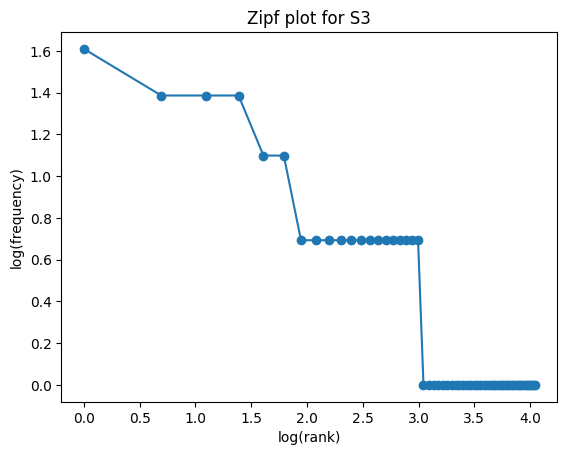

[(('.', 'please'), 5), (('is', 'running'), 4), (('running', 'slowly'), 4), (('please', 'help'), 4), (('help', '.'), 4)]
[(('running', 'slowly'), 4), (('please', 'help'), 4), (('crashes', 'opening'), 2), (('python', 'running'), 2), (('uploading', 'file'), 2)]


In [9]:
S1 = [t for r in res for t in r['tokens']]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [w for r in res for w in r['final']]
S4 = [porter.stem(w) for w in S3]

def stats(s):
    return len(s), len(set(s)), round(len(set(s)) / len(s), 4)

st = pd.DataFrame([stats(S1), stats(S2), stats(S3), stats(S4)],
                  index=['S1', 'S2', 'S3', 'S4'], columns=['total', 'unique', 'TTR'])
display(st)

print(Counter(S1).most_common(10))
print(Counter(S3).most_common(10))

freq = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freq) + 1)
plt.plot(np.log(ranks), np.log(freq), marker='o')
plt.xlabel('log(rank)')
plt.ylabel('log(frequency)')
plt.title('Zipf plot for S3')
plt.show()

print(Counter(b for r in res for b in nltk.bigrams(r['tokens'])).most_common(5))
print(Counter(b for r in res for b in nltk.bigrams(r['final'])).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer: The S1 top words are . (18) and the (12). The S3 top words are check, n't, laptop, works, another and computer (3 each). Bigrams are built per ticket, so none spans two tickets. The top S3 bigram is (works, another). With only 52 unique words the Zipf plot will look jagged, which is normal for a dataset this small.*

Q6.

(a) TTR rises from 0.52 (S1) to 0.58 (S2) to 0.71 (S3). The most repeated tokens are . (18 times) and the (12 times), so removing punctuation and stopwords cuts total tokens (155 → 73) much faster than unique tokens (81 → 52). From S3 to S4 it falls to 0.68. Stemming keeps the total at 73 but merges variants (opening/open → open, working/works → work), so unique words drop from 52 to 50.

(b) isn't: my tokenizer gives ["isn't"], while word_tokenize gives ["is", "n't"]. NLTK uses Treebank rules that split a contraction into the verb and the negation. Mine treats an apostrophe inside a word as part of the word. The same happens with +91 98765 43210, which is one token in mine and three in NLTK.

(c) Porter stems changed → chang and tried → tri, neither of which is a real word. It also stems several → sever, which is a different word with a different meaning.

(d) tried: Porter gives tri. The POS-aware lemmatizer tags it as a past-participle verb and returns try, which is a real word with the same meaning. changed → change and jammed → jam work the same way.